# 2.4 - Clasificación binaria: abandono de clientes (Churn)

Predeciremos si un cliente **abandona una entidad bancaria** a partir de su perfil. El objetivo `Exited` tiene dos clases: **0 = permanece y 1 = abandona**. La clase positiva de precision, recall y F1 será **1 = abandona**.

Seguiremos un método sencillo:

1. Cargar los datos y revisar la distribución del target.
2. Separar entrenamiento y test con una partición estratificada.
3. Transformar las variables y normalizarlas usando solo entrenamiento.
4. Definir una red neuronal densa.
5. Elegir la función de pérdida y el optimizador.
6. Entrenar mostrando únicamente **accuracy** como métrica.
7. Representar la pérdida y accuracy y, después, precision, recall y F1.
8. Evaluar el modelo y mostrar las matrices de confusión.

Separamos antes de ajustar el preprocesado para que test no participe en el aprendizaje de escalas o categorías. Usamos **solo entrenamiento y test**, sin tercer conjunto.

**Notebook preparado sin ejecutar.** Los resultados y las gráficas se generarán al ejecutar las celdas. Referencia de las métricas: `BonusTrack_03_Evaluacion_Modelos_Clasificacion.ipynb`.

**Material de origen:** `6_01_04_Redes_Neuronales_Clasificacion_TensorFlow.ipynb, apartado 1`.

---
## 1. Carga de datos

Utilizamos el CSV de la asignatura. Las etiquetas se conservan como enteros; el target no se normaliza.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, classification_report, ConfusionMatrixDisplay)
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import Callback

SEMILLA = 42
tf.keras.utils.set_random_seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

df = pd.read_csv("datasets/Churn.csv")
target_col = "Exited"
CLASES = np.array([0, 1])
NOMBRES = ['Permanece', 'Abandona']
display(df.head(5))
print(f"{len(df):,} observaciones y {df.shape[1] - 1} variables de entrada.")
if df.isna().any().any():
    raise ValueError("Hay valores ausentes: revisa su tratamiento antes de continuar.")

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


10,000 observaciones y 10 variables de entrada.


### 1.1. Distribución del target

Contamos las observaciones y el porcentaje de cada clase y mostramos un gráfico de barras. Una accuracy elevada puede ocultar un mal resultado en una clase minoritaria: también examinaremos precision, recall y F1.

,Clase,Significado,Observaciones,Porcentaje
0,0,Permanece,7963,79.63
1,1,Abandona,2037,20.37


Valora el desbalance junto con los errores de cada clase.


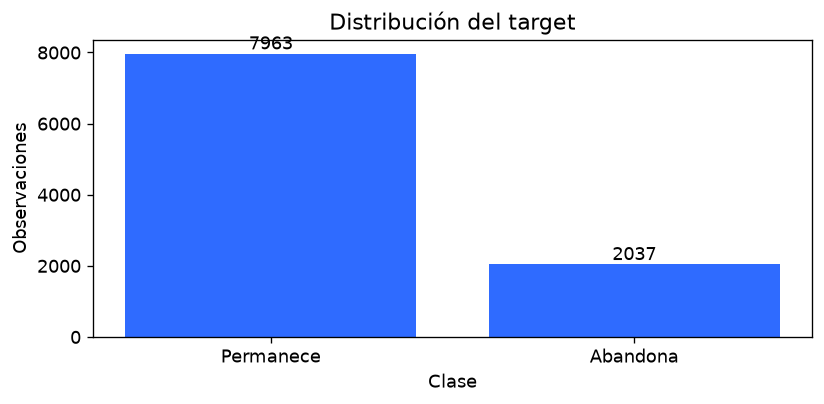

In [2]:
conteos = df[target_col].value_counts().reindex(CLASES, fill_value=0)
distribucion = pd.DataFrame({
    "Clase": CLASES,
    "Significado": NOMBRES,
    "Observaciones": conteos.to_numpy(),
    "Porcentaje": 100 * conteos.to_numpy() / len(df),
})
display(distribucion)
print("Valora el desbalance junto con los errores de cada clase.")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(NOMBRES, conteos.to_numpy(), color="#2F6BFF")
ax.set(title="Distribución del target", xlabel="Clase", ylabel="Observaciones")
ax.bar_label(ax.containers[0])
fig.tight_layout()
plt.show()

En el CSV proporcionado hay **7.963 clientes que permanecen y 2.037 que abandonan**. Las clases están desbalanceadas. Compensaremos el desbalance con `class_weight`, calculado únicamente con las etiquetas de entrenamiento. No interpretaremos accuracy de forma aislada.

---
## 2. Partición en entrenamiento y test

Reservamos el 20 % para test. `stratify=y` conserva aproximadamente la proporción de clases de la muestra. Test no actualiza los pesos y no se utiliza para elegir épocas, arquitectura, umbral ni hiperparámetros.

In [3]:
X = df.drop(columns=target_col).copy()
y = df[target_col].astype("int32")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)
y_train_array = y_train.to_numpy()
y_test_array = y_test.to_numpy()
print(f"Entrenamiento: {len(X_train)} | Test: {len(X_test)}")
display(pd.DataFrame({
    "Train (%)": y_train.value_counts(normalize=True).reindex(CLASES) * 100,
    "Test (%)": y_test.value_counts(normalize=True).reindex(CLASES) * 100,
}))

Entrenamiento: 8000 | Test: 2000


,Train (%),Test (%)
Exited,,
0,79.625,79.65
1,20.375,20.35


---
## 3. Transformación y normalización

Las variables numéricas se escalan con **MinMaxScaler**. Las categóricas se representan mediante **one-hot**, sin inventar un orden. Los codificadores y el escalador se ajustan solo con entrenamiento y se reutilizan en test.

En Churn, `Geography` y `Gender` son categóricas. El número de entradas de la red se obtiene después de codificarlas, porque una variable puede convertirse en varias columnas.

In [4]:
numericas = X_train.select_dtypes(include="number").columns.tolist()
categoricas = X_train.select_dtypes(exclude="number").columns.tolist()
preprocesador = ColumnTransformer([
    ("numericas", MinMaxScaler(), numericas),
    ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
], sparse_threshold=0)

X_train_n = preprocesador.fit_transform(X_train).astype("float32")
X_test_n = preprocesador.transform(X_test).astype("float32")
print("Dimensión de entrada tras transformar:", X_train_n.shape[1])
display(pd.DataFrame(X_train_n[:5], columns=preprocesador.get_feature_names_out()))

Dimensión de entrada tras transformar: 13


,numericas__CreditScore,numericas__Age,numericas__Tenure,numericas__Balance,numericas__NumOfProducts,numericas__HasCrCard,numericas__IsActiveMember,numericas__EstimatedSalary,categoricas__Geography_France,categoricas__Geography_Germany,categoricas__Geography_Spain,categoricas__Gender_Female,categoricas__Gender_Male
0,0.362,0.391892,0.6,0.000000,0.000000,0.0,0.0,0.975027,1.0,0.0,0.0,1.0,0.0
1,0.748,0.243243,0.6,0.377106,0.333333,1.0,1.0,0.053083,0.0,1.0,0.0,0.0,1.0
2,0.268,0.148649,0.4,0.518595,0.000000,1.0,0.0,0.820110,1.0,0.0,0.0,1.0,0.0
3,0.610,0.256757,0.6,0.434812,0.333333,1.0,0.0,0.008821,1.0,0.0,0.0,0.0,1.0
4,0.230,0.202703,0.5,0.000000,0.333333,0.0,1.0,0.393470,1.0,0.0,0.0,0.0,1.0


---
## 4. Arquitectura de la red neuronal

Usamos dos capas ocultas sencillas: **32 y 16 neuronas con ReLU**.

La salida tiene **una neurona sigmoide**, que estima la probabilidad de abandono. Convertimos esa probabilidad en clase usando un umbral fijo de **0,5**: clase 1 si $p\geq0,5$ y clase 0 en otro caso.

In [5]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEMILLA)
model = Sequential([
    Input(shape=(X_train_n.shape[1],)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 993 (3.88 KB)

 Trainable params: 993 (3.88 KB)

 Non-trainable params: 0 (0.00 B)

---
## 5. Pérdida, optimizador y métrica de entrenamiento

Elegimos **binary crossentropy** porque el objetivo es binario y la salida es sigmoide.

Usamos **Adam**, con tasa de aprendizaje 0,001. La única métrica de `compile` es **accuracy**. Precision, recall y F1 se calcularán después del entrenamiento.

In [6]:
EPOCHS = 50
BATCH_SIZE = 32
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"])

---
## 6. Entrenamiento: mostramos solo accuracy

Al acabar cada época, guardamos las probabilidades de entrenamiento y test con los mismos pesos. El callback **solo muestra accuracy**. Una vez finalizado `fit`, utilizaremos las probabilidades guardadas para calcular todas las curvas, sin reentrenar ni modificar los pesos.

Las predicciones se guardan en memoria para este ejemplo pequeño. Las consultas a test son solo didácticas: si decidimos cambios mirando esas curvas, test deja de ser una evaluación final independiente. No usamos `validation_data` ni un tercer conjunto.

### 6.1. Compensación del desbalance con `class_weight`

Calculamos un peso inversamente proporcional a la frecuencia de cada clase **solo con `y_train`**:

$$w_c = \frac{N_{train}}{K\,n_c}$$

Aquí, $K$ es el número de clases y $n_c$ el número de ejemplos de la clase $c$ en entrenamiento. La clase minoritaria **abandona (1)** recibe más peso. Para el mismo error de predicción, un ejemplo de esa clase contribuye más a la pérdida que uno de la clase mayoritaria.

Así, cada clase tiene la misma suma total de pesos, sin duplicar ni eliminar observaciones. No cambia las etiquetas ni el umbral fijo de 0,5, pero sí puede cambiar las probabilidades aprendidas por el modelo. Puede mejorar la detección de la minoritaria, pero también aumentar los falsos positivos: revisaremos precision, recall, F1 y la matriz de confusión.

Después pasamos el diccionario a `model.fit(..., class_weight=class_weight)`. El test no interviene en el cálculo de los pesos.

**Cambio de configuración:** se han retirado las salidas del entrenamiento anterior sin pesos. Vuelve a ejecutar desde la definición de la arquitectura para reinicializar el modelo y obtener resultados de la nueva configuración. No se ha reentrenado el modelo al editar el notebook.

In [7]:
from sklearn.utils.class_weight import compute_class_weight

clases_train = np.unique(y_train_array)
pesos_train = compute_class_weight(class_weight="balanced", classes=clases_train, y=y_train_array)
class_weight = dict(zip(clases_train.tolist(), pesos_train.tolist()))

conteos_train = pd.Series(y_train_array).value_counts().reindex(clases_train)
display(pd.DataFrame({
    "Clase": clases_train,
    "Significado": [NOMBRES[int(c)] for c in clases_train],
    "Ejemplos de entrenamiento": conteos_train.to_numpy(),
    "Peso": pesos_train}))
print("class_weight:", class_weight)

,Clase,Significado,Ejemplos de entrenamiento,Peso
0,0,Permanece,6370,0.627943
1,1,Abandona,1630,2.453988


class_weight: {0: 0.6279434850863422, 1: 2.4539877300613497}


In [8]:
def obtener_clases(probabilidades):
    return (probabilidades.ravel() >= 0.5).astype("int32")


class GuardarEvolucion(Callback):
    def on_train_begin(self, logs=None):
        self.probabilidades_por_epoch = []

    def on_epoch_end(self, epoch, logs=None):
        p_train = self.model(X_train_n, training=False).numpy()
        p_test = self.model(X_test_n, training=False).numpy()
        self.probabilidades_por_epoch.append((p_train, p_test))
        acc_train = accuracy_score(y_train_array, obtener_clases(p_train))
        acc_test = accuracy_score(y_test_array, obtener_clases(p_test))
        print(f"Epoch {epoch + 1:02d}/{self.params['epochs']} | "
              f"accuracy train: {acc_train:.4f} | accuracy test: {acc_test:.4f}")


seguimiento = GuardarEvolucion()
history = model.fit(
    X_train_n, y_train_array,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=[seguimiento], shuffle=True, verbose=0,
)

Epoch 01/50 | accuracy train: 0.6814 | accuracy test: 0.6835
Epoch 02/50 | accuracy train: 0.7035 | accuracy test: 0.7005
Epoch 03/50 | accuracy train: 0.7391 | accuracy test: 0.7280
Epoch 04/50 | accuracy train: 0.7468 | accuracy test: 0.7365
Epoch 05/50 | accuracy train: 0.7638 | accuracy test: 0.7580
Epoch 06/50 | accuracy train: 0.7735 | accuracy test: 0.7695
Epoch 07/50 | accuracy train: 0.7841 | accuracy test: 0.7755
Epoch 08/50 | accuracy train: 0.7889 | accuracy test: 0.7840
Epoch 09/50 | accuracy train: 0.7910 | accuracy test: 0.7865
Epoch 10/50 | accuracy train: 0.7967 | accuracy test: 0.7915
Epoch 11/50 | accuracy train: 0.8009 | accuracy test: 0.7960
Epoch 12/50 | accuracy train: 0.8031 | accuracy test: 0.8020
Epoch 13/50 | accuracy train: 0.8049 | accuracy test: 0.8015
Epoch 14/50 | accuracy train: 0.8073 | accuracy test: 0.8045
Epoch 15/50 | accuracy train: 0.8094 | accuracy test: 0.8035
Epoch 16/50 | accuracy train: 0.8129 | accuracy test: 0.8045
Epoch 17/50 | accuracy t

---
## 7. Cálculo de las métricas después de entrenar

* **Accuracy:** proporción global de etiquetas correctas.
* **Precision:** de los positivos predichos, proporción que realmente es positiva.
* **Recall:** de los positivos reales, proporción detectada.
* **F1:** media armónica de precision y recall.

En binaria, precision, recall y F1 se refieren a **Exited=1 (abandona)**. El umbral permanece fijado en 0,5 para todas las épocas.

Usamos `zero_division=0`: si no hay predicciones positivas para una clase, una división no definida se representa como 0. La pérdida se calcula con las probabilidades; las otras métricas, con las clases predichas.

**Ponderación y evaluación:** `class_weight` modifica la pérdida usada para entrenar. Para comparar los dos conjuntos en la misma escala, las curvas y la tabla final muestran crossentropy **sin ponderar**, así como accuracy, precision, recall y F1 sin pesos de clase. Por tanto, esa curva de pérdida no es el objetivo ponderado que aparece en `history.history["loss"]`.

In [9]:
def calcular_metricas(reales, probabilidades):
    predichas = obtener_clases(probabilidades)
    return {
        "loss": log_loss(reales, probabilidades.ravel(), labels=CLASES),
        "accuracy": accuracy_score(reales, predichas),
        "precision": precision_score(reales, predichas, average="binary", pos_label=1, zero_division=0),
        "recall": recall_score(reales, predichas, average="binary", pos_label=1, zero_division=0),
        "f1": f1_score(reales, predichas, average="binary", pos_label=1, zero_division=0)}


registros = []
for epoch, (p_train, p_test) in enumerate(seguimiento.probabilidades_por_epoch, start=1):
    fila = {"epoch": epoch}
    for nombre, reales, probabilidades in [
        ("train", y_train_array, p_train), ("test", y_test_array, p_test)
    ]:
        for metrica, valor in calcular_metricas(reales, probabilidades).items():
            fila[f"{metrica}_{nombre}"] = valor
    registros.append(fila)
evolucion = pd.DataFrame(registros).set_index("epoch")
display(evolucion.tail(5))

,loss_train,accuracy_train,precision_train,recall_train,f1_train,loss_test,accuracy_test,precision_test,recall_test,f1_test
epoch,,,,,,,,,,
46,0.395217,0.819375,0.541498,0.740491,0.625551,0.412115,0.8145,0.533088,0.712531,0.609884
47,0.394375,0.820625,0.544098,0.738037,0.626399,0.411614,0.8135,0.531250,0.710074,0.607781
48,0.393506,0.821000,0.544796,0.738650,0.627083,0.410766,0.8145,0.533333,0.707617,0.608237
49,0.394211,0.819875,0.542510,0.739877,0.626006,0.411751,0.8135,0.531136,0.712531,0.608604
50,0.393447,0.820250,0.543360,0.738037,0.625911,0.411335,0.8120,0.528545,0.705160,0.604211


---
## 8. Curvas de entrenamiento y test

Primero representamos **pérdida y accuracy** en una fila de dos columnas. Después, **precision, recall y F1** en otra fila de tres columnas. Se muestran todas las épocas. Azul indica entrenamiento y rojo test.

Estos valores se calculan al terminar cada época, con los mismos pesos para los dos conjuntos. Pueden diferir de los promedios internos por lote que registra `history`, porque durante una época los pesos van cambiando.

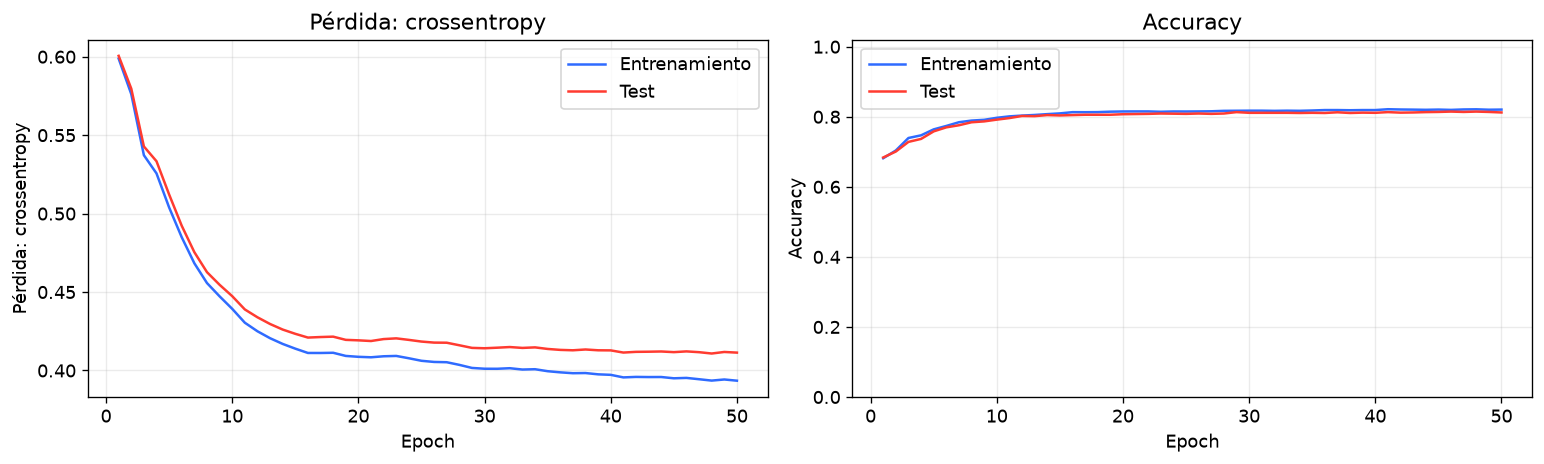

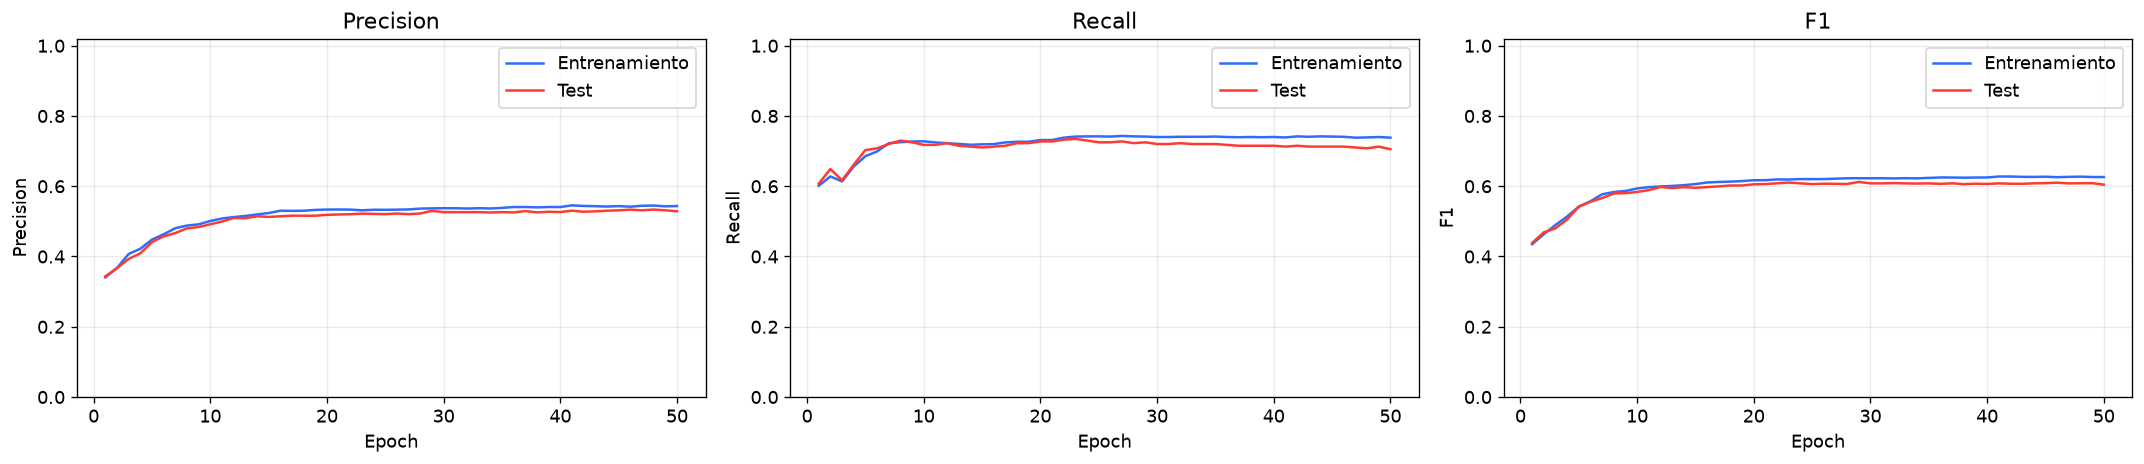

In [10]:
def dibujar_metrica(ax, metrica, titulo, es_proporcion=True):
    ax.plot(evolucion.index, evolucion[f"{metrica}_train"],
            color="#2F6BFF", label="Entrenamiento")
    ax.plot(evolucion.index, evolucion[f"{metrica}_test"],
            color="#FF3B30", label="Test")
    ax.set(title=titulo, xlabel="Epoch", ylabel=titulo)
    if es_proporcion:
        ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
dibujar_metrica(axes[0], "loss", "Pérdida: crossentropy", es_proporcion=False)
dibujar_metrica(axes[1], "accuracy", "Accuracy")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metrica, titulo in zip(axes, ["precision", "recall", "f1"], ["Precision", "Recall", "F1"]):
    dibujar_metrica(ax, metrica, titulo)
fig.tight_layout()
plt.show()

---
## 9. Evaluación final y resultados por clase

Calculamos las métricas finales sobre entrenamiento y test y mostramos un informe por clase. Como referencia sencilla, calculamos la accuracy de predecir siempre la clase mayoritaria **del entrenamiento**.

Consulta `BonusTrack_03_Evaluacion_Modelos_Clasificacion.ipynb` para ver los cálculos de las métricas con ejemplos pequeños y la interpretación de los promedios.

In [11]:
p_train_final = model.predict(X_train_n, verbose=0)
p_test_final = model.predict(X_test_n, verbose=0)
pred_train = obtener_clases(p_train_final)
pred_test = obtener_clases(p_test_final)

resultados = pd.DataFrame({
    "Entrenamiento": calcular_metricas(y_train_array, p_train_final),
    "Test": calcular_metricas(y_test_array, p_test_final),
}).T
display(resultados)
clase_mayoritaria = y_train.value_counts().idxmax()
pred_base = np.full(len(y_test_array), clase_mayoritaria)
print(f"Accuracy base en test (siempre clase {clase_mayoritaria}): "
      f"{accuracy_score(y_test_array, pred_base):.4f}")

for nombre, reales, predichas in [
    ("Entrenamiento", y_train_array, pred_train),
    ("Test", y_test_array, pred_test),
]:
    print(f"\n{nombre}")
    print(classification_report(reales, predichas, labels=CLASES,
                                target_names=NOMBRES, zero_division=0, digits=4))

,loss,accuracy,precision,recall,f1
Entrenamiento,0.393447,0.82025,0.543360,0.738037,0.625911
Test,0.411335,0.81200,0.528545,0.705160,0.604211


Accuracy base en test (siempre clase 0): 0.7965

Entrenamiento
              precision    recall  f1-score   support

   Permanece     0.9262    0.8413    0.8817      6370
    Abandona     0.5434    0.7380    0.6259      1630

    accuracy                         0.8203      8000
   macro avg     0.7348    0.7897    0.7538      8000
weighted avg     0.8482    0.8203    0.8296      8000


Test
              precision    recall  f1-score   support

   Permanece     0.9176    0.8393    0.8767      1593
    Abandona     0.5285    0.7052    0.6042       407

    accuracy                         0.8120      2000
   macro avg     0.7231    0.7722    0.7405      2000
weighted avg     0.8385    0.8120    0.8213      2000



### 9.1. Comparación visual de las métricas finales

El panel de **dos filas y dos columnas** compara entrenamiento (azul) y test (naranja) para el único modelo de red neuronal. Cada pareja de barras representa accuracy, precision, recall o F1 al finalizar el entrenamiento. Todos los ejes tienen la misma escala y las barras muestran el valor numérico.

Precision, recall y F1 se refieren a la clase positiva: abandona.

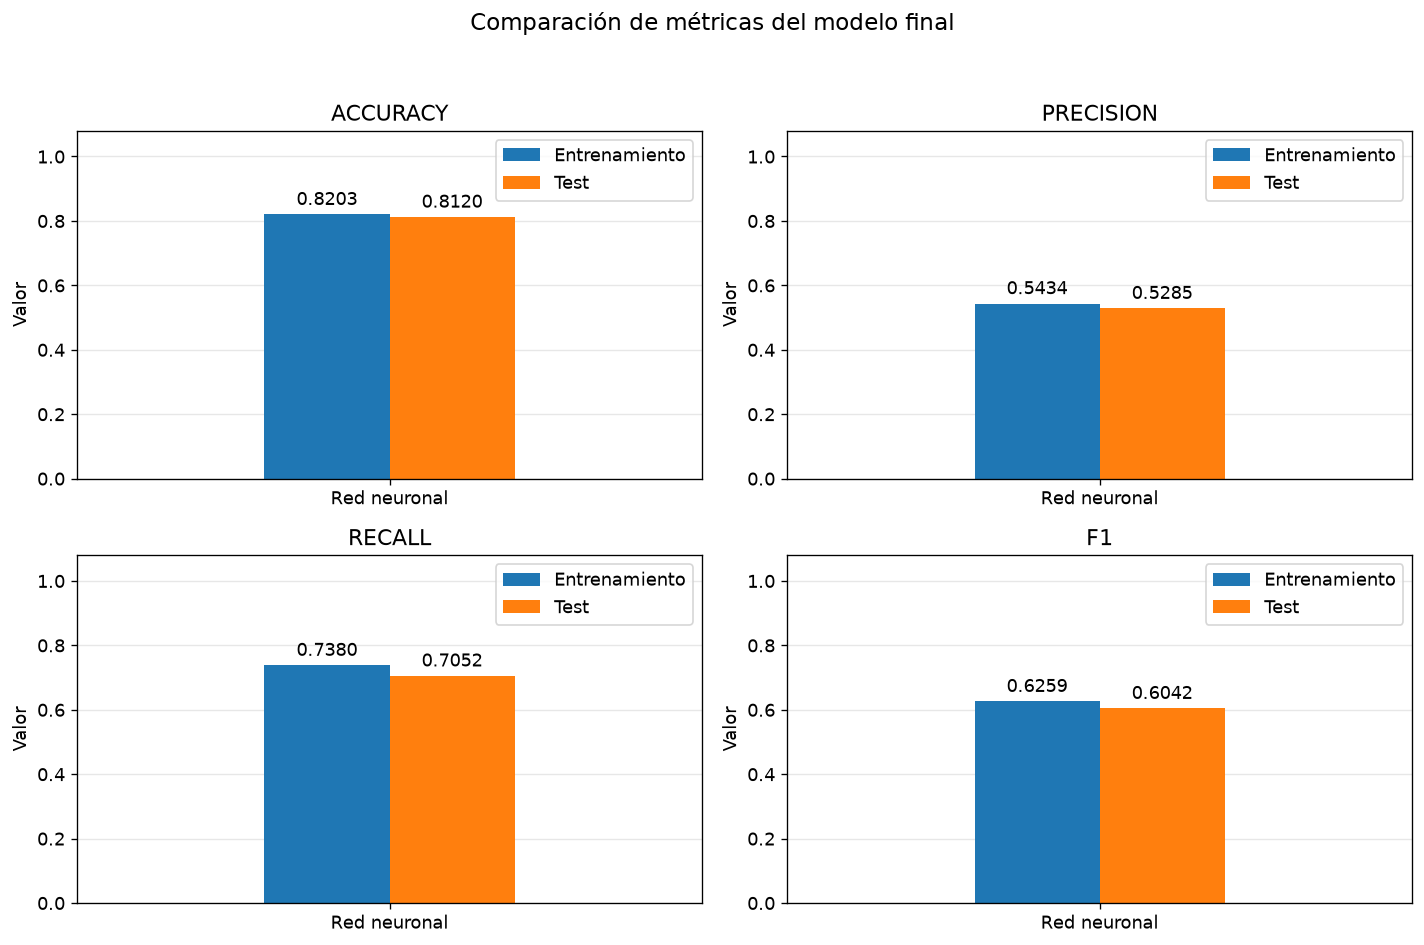

In [12]:
metricas_panel = ["accuracy", "precision", "recall", "f1"]
titulos_panel = ["ACCURACY", "PRECISION", "RECALL", "F1"]
comparacion_metricas = resultados.loc[["Entrenamiento", "Test"], metricas_panel]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ancho = 0.32
for ax, metrica, titulo in zip(axes.flat, metricas_panel, titulos_panel):
    valor_train = float(comparacion_metricas.loc["Entrenamiento", metrica])
    valor_test = float(comparacion_metricas.loc["Test", metrica])
    barras_train = ax.bar(-ancho / 2, valor_train, width=ancho, label="Entrenamiento")
    barras_test = ax.bar(ancho / 2, valor_test, width=ancho, label="Test")
    ax.bar_label(barras_train, fmt="%.4f", padding=3)
    ax.bar_label(barras_test, fmt="%.4f", padding=3)
    ax.set(title=titulo, ylabel="Valor", ylim=(0, 1.08), xlim=(-0.8, 0.8))
    ax.set_xticks([0], ["Red neuronal"])
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="upper right")

fig.suptitle("Comparación de métricas del modelo final", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

---
## 10. Matrices de confusión

Las **filas representan clases reales** y las **columnas clases predichas**. La diagonal contiene los aciertos. Usamos el mismo orden de clases en los dos conjuntos y mostramos **recuentos**, no porcentajes.

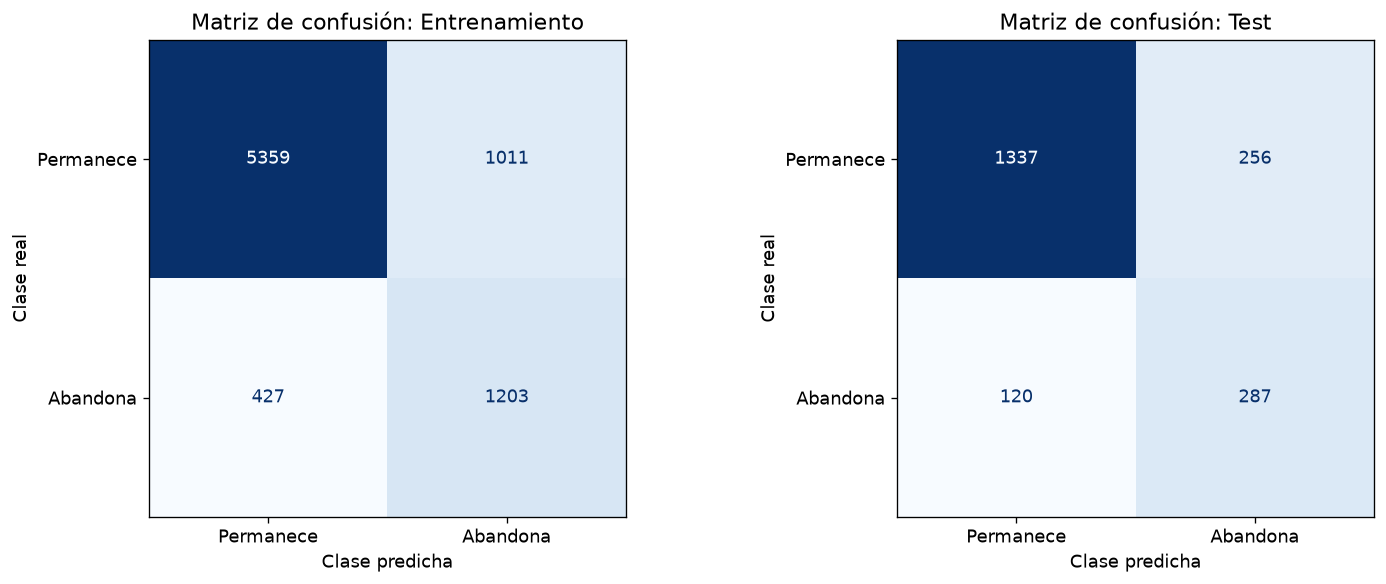

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, reales, predichas, titulo in [
    (axes[0], y_train_array, pred_train, "Entrenamiento"),
    (axes[1], y_test_array, pred_test, "Test"),
]:
    ConfusionMatrixDisplay.from_predictions(
        reales, predichas, labels=CLASES, display_labels=NOMBRES,
        values_format="d", cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set(title=f"Matriz de confusión: {titulo}",
           xlabel="Clase predicha", ylabel="Clase real")
fig.tight_layout()
plt.show()

### Preguntas para interpretar los resultados

* ¿Supera el modelo al clasificador de la clase mayoritaria?
* ¿Qué clases detecta mejor y cuáles confunde?
* ¿Son parecidos los errores en entrenamiento y test?
* ¿Qué información añade F1 a accuracy?

